In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/bank-full.csv", sep=";")
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [95]:
print(df.shape)          # rows and columns
print(df["y"].value_counts(normalize=True))   # share of yes / no
df.isna().sum()          # missing values

(45211, 17)
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [96]:
# y: turn "yes"/"no" into 1/0
df["y"] = (df["y"] == "yes").astype(int)

# LEAKAGE CHECK: duration is only known AFTER the call, so remove it
df = df.drop(columns=["duration"])

# pdays = -1 means "never contacted before", so make that clear
df["contacted_before"] = (df["pdays"] != -1).astype(int)
df.loc[df["pdays"] == -1, "pdays"] = 0

In [97]:
split_point = int(len(df) * 0.8)
train = df.iloc[:split_point]
test = df.iloc[split_point:]

X_train, y_train = train.drop(columns="y"), train["y"]
X_test, y_test = test.drop(columns="y"), test["y"]

In [98]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(exclude="object").columns.tolist()

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", "passthrough", num_cols),
])

model = Pipeline([
    ("prep", prep),
    ("clf", HistGradientBoostingClassifier(random_state=42)),
])

model.fit(X_train, y_train)

/var/folders/p6/rc4sx3g56gj1plw6w7_vff240000gn/T/ipykernel_99754/3651974762.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include="object").columns.tolist()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'previous','poutcome','contacted_before']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining col

In [99]:
from sklearn.metrics import roc_auc_score, average_precision_score

scores = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, scores), 3))
print("PR-AUC :", round(average_precision_score(y_test, scores), 3))

ROC-AUC: 0.676
PR-AUC : 0.467


Call top 10% -> find 16% of all yes (1.6x lift)
Call top 20% -> find 33% of all yes (1.6x lift)
Call top 30% -> find 48% of all yes (1.6x lift)


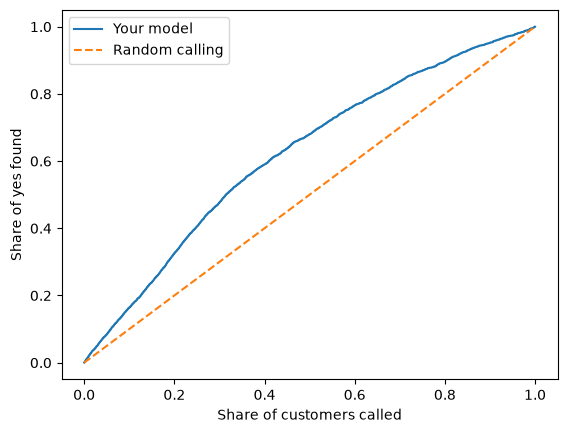

In [100]:
def gain_table(y_true, scores):
    d = pd.DataFrame({"y": y_true.values, "score": scores})
    d = d.sort_values("score", ascending=False).reset_index(drop=True)
    d["pct_called"] = (d.index + 1) / len(d)
    d["pct_yes_found"] = d["y"].cumsum() / d["y"].sum()
    return d

gt = gain_table(y_test, scores)

for p in [0.1, 0.2, 0.3]:
    found = gt.loc[int(len(gt) * p) - 1, "pct_yes_found"]
    print(f"Call top {int(p*100)}% -> find {found:.0%} of all yes ({found/p:.1f}x lift)")

plt.plot(gt["pct_called"], gt["pct_yes_found"], label="Your model")
plt.plot([0, 1], [0, 1], "--", label="Random calling")
plt.xlabel("Share of customers called")
plt.ylabel("Share of yes found")
plt.legend()
plt.show()

In [101]:
cost_per_call = 5      # assumption
profit_per_sale = 100  # assumption

gt["profit"] = gt["y"].cumsum() * profit_per_sale - (gt.index + 1) * cost_per_call
best = gt["profit"].idxmax()
print("Best number of calls:", best + 1, "out of", len(gt))
print("Best share to call:", round(gt.loc[best, "pct_called"], 2))

Best number of calls: 9043 out of 9043
Best share to call: 1.0


In [102]:
import joblib

joblib.dump(model, "../model/model.joblib")
gt.to_csv("../model/gain_table.csv", index=False)
X_train.head(1).to_csv("../model/sample_row.csv", index=False)

In [103]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

raw.groupby("job")["converted"].mean().sort_values(ascending=False)

job
student          0.286780
retired          0.227915
unemployed       0.155027
management       0.137556
admin.           0.122027
self-employed    0.118429
unknown          0.118056
technician       0.110570
services         0.088830
housemaid        0.087903
entrepreneur     0.082717
blue-collar      0.072750
Name: converted, dtype: float64

In [104]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

raw.groupby("month")["converted"].mean().sort_values(ascending=False)

month
mar    0.519916
dec    0.467290
sep    0.464594
oct    0.437669
apr    0.196794
feb    0.166478
aug    0.110133
jun    0.102228
nov    0.101511
jan    0.101212
jul    0.090935
may    0.067195
Name: converted, dtype: float64

In [105]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

raw.groupby("education")["converted"].mean().sort_values(ascending=False)

education
tertiary     0.150064
unknown      0.135703
secondary    0.105594
primary      0.086265
Name: converted, dtype: float64

In [106]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

raw.groupby("marital")["converted"].mean().sort_values(ascending=False)

marital
single      0.149492
divorced    0.119455
married     0.101235
Name: converted, dtype: float64

In [107]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

raw.groupby("poutcome")["converted"].mean().sort_values(ascending=False)

poutcome
success    0.647253
other      0.166848
failure    0.126097
unknown    0.091615
Name: converted, dtype: float64

In [108]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int) 
raw["converted"].mean()

np.float64(0.11698480458295547)

In [109]:
print("Train yes rate:", round(y_train.mean() * 100, 1), "%")
print("Test yes rate :", round(y_test.mean() * 100, 1), "%")

Train yes rate: 6.7 %
Test yes rate : 31.6 %


In [110]:
raw = pd.read_csv("../data/bank-full.csv", sep=";")
raw["converted"] = (raw["y"] == "yes").astype(int)

def best(col):
    r = raw.groupby(col)["converted"].mean().sort_values(ascending=False)
    return f"{r.index[0]} ({r.iloc[0]*100:.1f}%)"

def worst(col):
    r = raw.groupby(col)["converted"].mean().sort_values(ascending=False)
    return f"{r.index[-1]} ({r.iloc[-1]*100:.1f}%)"

student = raw[raw["job"] == "student"]["converted"].mean() * 100
trap = "Not given to Claude; should say it does not have this"

rows = [
    ("Which job converts best?", best("job")),
    ("Which job converts worst?", worst("job")),
    ("Which month converts best?", best("month")),
    ("Which education level converts best?", best("education")),
    ("Which marital status converts best?", best("marital")),
    ("Which previous campaign outcome converts best?", best("poutcome")),
    ("What is the overall conversion rate?", f"{raw['converted'].mean()*100:.1f}%"),
    ("What is the conversion rate for students?", f"{student:.1f}%"),
    ("What is the average customer balance?", trap),
    ("Do customers with a housing loan convert more?", trap),
]

print("| Question | Correct answer (pandas) | Claude's answer | Pass/Fail |")
print("|---|---|---|---|")
for q, a in rows:
    print(f"| {q} | {a} |  |  |")

| Question | Correct answer (pandas) | Claude's answer | Pass/Fail |
|---|---|---|---|
| Which job converts best? | student (28.7%) |  |  |
| Which job converts worst? | blue-collar (7.3%) |  |  |
| Which month converts best? | mar (52.0%) |  |  |
| Which education level converts best? | tertiary (15.0%) |  |  |
| Which marital status converts best? | single (14.9%) |  |  |
| Which previous campaign outcome converts best? | success (64.7%) |  |  |
| What is the overall conversion rate? | 11.7% |  |  |
| What is the conversion rate for students? | 28.7% |  |  |
| What is the average customer balance? | Not given to Claude; should say it does not have this |  |  |
| Do customers with a housing loan convert more? | Not given to Claude; should say it does not have this |  |  |
